<div align="center" style="padding:40px 24px;background:linear-gradient(135deg,#0e1a2e 0%,#13223b 100%);border-radius:14px;border-bottom:5px solid #ffd43b;">
  <p style="margin:0;color:#6aaef0;font-family:monospace;font-weight:700;font-size:14px;letter-spacing:.16em;text-transform:uppercase;">The AI Learning Hub · Lesson 03 · Applied AI: unstructured data</p>
  <h1 style="margin:14px 0 6px;color:#f1f5fb;font-size:42px;">04 · Cats vs dogs, and our pets</h1>
  <p style="margin:0;color:#b4c2d8;font-size:18px;">From scratch or borrowed knowledge? And does it work on <i>our</i> animals?</p>
</div>

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/the-ai-learning-hub/03-applied-ai-projects/blob/main/02_computer_vision/02_project_cats_vs_dogs/04_Cats_vs_Dogs_And_Our_Pets.ipynb) [![Slides](https://img.shields.io/badge/slides-Lesson_03-ffd43b)](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#cats-dogs)

## 🎯 Objectives
By the end of this notebook you will be able to:

- load real photos from **explicit file lists**, look at them, and see a hand-made **convolution** find the edges of *our own pets*;
- use **data augmentation** and train a CNN **from scratch**, reading its training curves for **overfitting**;
- run a fair **CPU vs GPU race** and explain in plain words why the GPU wins;
- apply **transfer learning** (a pretrained MobileNetV3 + a new head trained in seconds) and compare it in a leaderboard;
- test the model on **our pets** (cropped vs original, an AI-generated dog), ask it **where it looked** with **Grad-CAM**, and try **your own photo**.

**📋 Prerequisites:** notebook 03 (pixels, kernels, CNN), Lesson 02 (overfitting, confusion matrix, PyTorch loop) · **▶️ How to use:** run the cells in order with `Shift`+`Enter`. On a laptop CPU the whole notebook takes ≈ 2–3 minutes (the first run also downloads a 21 MB model and caches the images and features).

## 📑 Contents

1. [🐾 Meet the data](#sec-1)
2. [🔍 A convolution on one of our pets](#sec-2)
3. [🎛️ Data augmentation: one photo, many photos](#sec-3)
4. [🧱 A CNN from scratch](#sec-4)
5. [🏁 The CPU vs GPU race](#sec-5)
6. [🎁 Transfer learning: borrow a trained eye](#sec-6)
7. [📏 Evaluation: confusion matrix and mistakes](#sec-7)
8. [🐶🐱 Our pets: the real test](#sec-8)
9. [📸 Try your own photo](#sec-9)
10. [✏️ Exercises](#sec-10)
11. [📌 Summary](#sec-11)
12. [📚 Learn more](#sec-12)

<a id="sec-0"></a>
## ⚙️ Setup

In [1]:
# ⚙️ Setup: works locally (VS Code / Jupyter) and in Google Colab
import os
import subprocess
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    ROOT = Path("/content/03-applied-ai-projects")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/the-ai-learning-hub/03-applied-ai-projects.git", str(ROOT)], check=True)
    os.chdir(ROOT)  # Colab already has torch, torchvision, matplotlib and ipywidgets: nothing to install
else:  # locally: walk up until we find the folder that has src/ and data/
    ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir() and (p / "data").is_dir())

sys.path.insert(0, str(ROOT))
print("Project root:", ROOT.name, "(Colab)" if IN_COLAB else "(local)")

Project root: 03-applied-ai-projects (local)


In [2]:
import io
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision.transforms.v2 as T
from IPython.display import display
from PIL import Image, ImageOps
from torch.utils.data import DataLoader, TensorDataset

from src.paths import cache_dir, models_dir
from src.plotting import CLASS_COLORS, PALETTE, apply_style, leaderboard, plot_confusion
from src.vision import (CLASSES, KERNELS, GradCAM, PetClassifier, SmallCNN, TensorImageDataset,
                        apply_kernel, available_devices, benchmark_training, best_device,
                        cats_dogs_files, center_crop_batch, count_parameters, device_name,
                        extract_features, ImageFileDataset, load_image, load_images_tensor,
                        normalize_imagenet, overlay_heatmap, pets_files, predict_proba,
                        pretrained_backbone, random_crop_flip, save_slide_image, set_seed, show_grid,
                        to_display, train_linear_head, train_model)

apply_style()
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("jpeg", pil_kwargs={"quality": 82})   # many photos: JPEG keeps the notebook light
SEED = 42
set_seed(SEED)
T_START = time.perf_counter()

# Heavy steps (30-epoch trainings, 4 backbones) are off by default: their results were saved in results/.
# Set RUN_HEAVY = True on a GPU (e.g. Colab → Runtime → Change runtime type → T4 GPU) to recompute them.
RUN_HEAVY = False
RESULTS = ROOT / "02_computer_vision" / "02_project_cats_vs_dogs" / "results"
DEVICE = best_device()

# Only the authors use this (EXPORT_SLIDES=1) to refresh the images in the slide deck.
EXPORT_SLIDES = os.environ.get("EXPORT_SLIDES") == "1"
def save_slide(fig, name):
    if EXPORT_SLIDES:
        save_slide_image(fig, ROOT / "assets" / "slides" / name)

print("PyTorch", torch.__version__, "| devices:", available_devices(), "| training on:", DEVICE, f"({device_name(DEVICE)})")

PyTorch 2.15.0+cpu | devices: ['cpu'] | training on: cpu (AMD Ryzen 7 7735HS with Radeon Graphics)


### 📖 Words you will meet (mini-glossary)

| Term | In plain words |
|---|---|
| **RGB channels** | a colour photo is three tables of numbers: red, green and blue |
| **data augmentation** | showing the model slightly changed copies of each photo (cropped, flipped, darker…) so it learns what does *not* matter |
| **global average pooling (GAP)** | turn each feature map into one number (its average): "how much of this pattern is in the photo?" |
| **overfitting** | the model memorises the training photos: great on them, worse on new ones (Lesson 02) |
| **GPU** | a graphics card: thousands of small calculators working at the same time |
| **pretrained backbone** | a big CNN already trained on 1.2 million ImageNet photos; we reuse its "eye" |
| **transfer learning** | keep the backbone frozen, train only a small new **head** for *our* question |
| **feature vector** | the list of numbers the backbone outputs for a photo (960 numbers here) |
| **Grad-CAM** | a heatmap of the regions of the photo that pushed the model towards its answer |

<a id="sec-1"></a>
# 1. 🐾 Meet the data

We use two sets of photos (details and licences in [`data/DATA_DICTIONARY.md`](../../data/DATA_DICTIONARY.md)):

| Set | What | Used for |
|---|---|---|
| `data/cats_and_dogs/` | 2,000 training + 1,000 validation photos from the Kaggle *Dogs vs. Cats* data (Microsoft Asirra), half cats and half dogs, resized to 256 px | training and validation |
| `data/pets/` | **the teacher's own animals**: 9 cats + 7 dogs, the full photo (`original/`) and a crop around the animal (`cropped/`) | the real-world test, at the end |

> ⚠️ **Watch out:** we always build **explicit, sorted lists of files** with their labels (`cats_dogs_files`). Evaluation code never uses a shuffled loader: a shuffled loader for predictions is a classic bug that misaligns predictions and labels (an old version of this lesson had it, and a good model looked like a coin toss).

In [3]:
p_tr, y_tr = cats_dogs_files("train")
p_va, y_va = cats_dogs_files("validation")
sizes = pd.DataFrame([Image.open(p).size for p in p_tr + p_va], columns=["width", "height"])
summary = pd.DataFrame({"cats": [int((y_tr == 0).sum()), int((y_va == 0).sum())],
                        "dogs": [int((y_tr == 1).sum()), int((y_va == 1).sum())]}, index=["train", "validation"])
display(summary)
print("first files:", [p.name for p in p_tr[:3]], "-> labels", y_tr[:3], "(0 = cat, 1 = dog)")
print(f"longest side: always {sizes.max(axis=1).max()} px | shortest side: {sizes.min(axis=1).min()} to "
      f"{sizes.min(axis=1).max()} px (median {int(sizes.min(axis=1).median())})")

,cats,dogs
train,1000,1000
validation,500,500


first files: ['cat.0.jpg', 'cat.1.jpg', 'cat.10.jpg'] -> labels [0 0 0] (0 = cat, 1 = dog)
longest side: always 256 px | shortest side: 41 to 256 px (median 192)


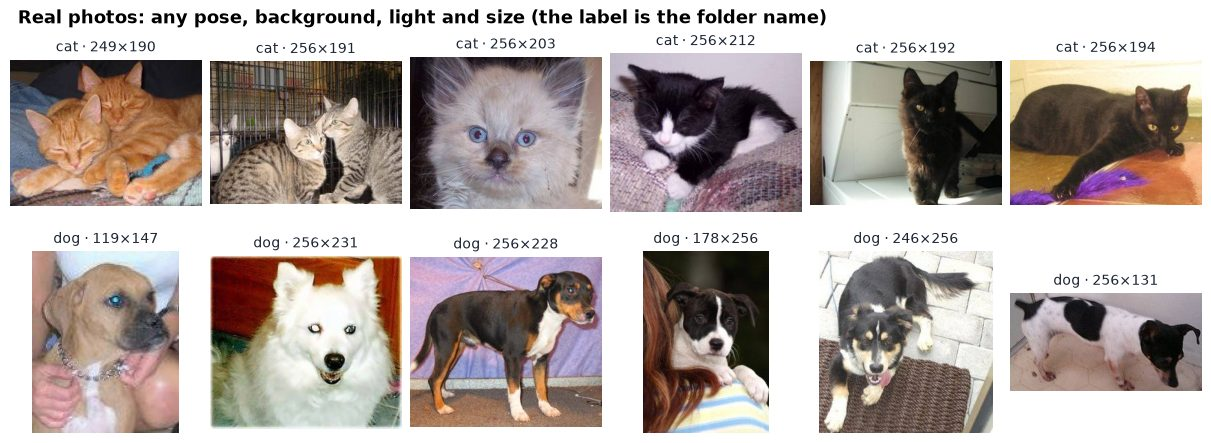

In [4]:
rng = np.random.default_rng(SEED)
pick = list(rng.choice(np.flatnonzero(y_tr == 0), 6, replace=False)) + list(rng.choice(np.flatnonzero(y_tr == 1), 6, replace=False))
imgs = [load_image(p_tr[k]) for k in pick]
fig = show_grid(imgs, [f"{CLASSES[y_tr[k]]} · {im.size[0]}×{im.size[1]}" for k, im in zip(pick, imgs)], ncols=6, size=2.0,
                suptitle="Real photos: any pose, background, light and size (the label is the folder name)")
plt.show()

### Our pets

These are the photos the model will **never** see during training. We will come back to them in section 8.

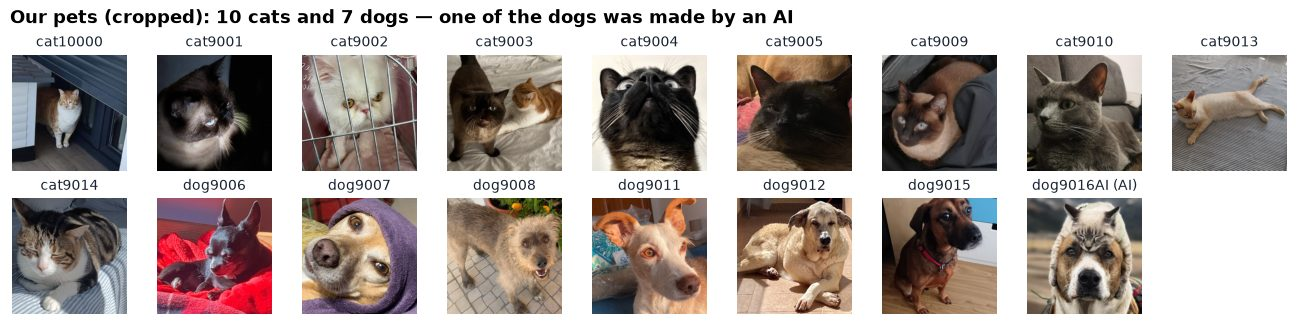

In [5]:
pets = pets_files("cropped")                 # 17 photos: 10 cats (one only in cropped/) + 7 dogs
pets_orig = pets_files("original")          # 16 full photos
pet_imgs = [load_image(p["path"]) for p in pets]
fig = show_grid([ImageOps.fit(im, (256, 256)) for im in pet_imgs],
                [p["name"] + (" (AI)" if p["ai_generated"] else "") for p in pets], ncols=9, size=1.45,
                suptitle="Our pets (cropped): 10 cats and 7 dogs — one of the dogs was made by an AI")
plt.show()

## 🧠 How it works: a colour photo is three tables

In notebook 03 one image was **one** table of numbers. A colour photo has **three** of the same size: how much **red**, **green** and **blue** light each pixel has (0–255). A 256 × 256 colour photo is therefore 256 × 256 × 3 = 196,608 numbers.

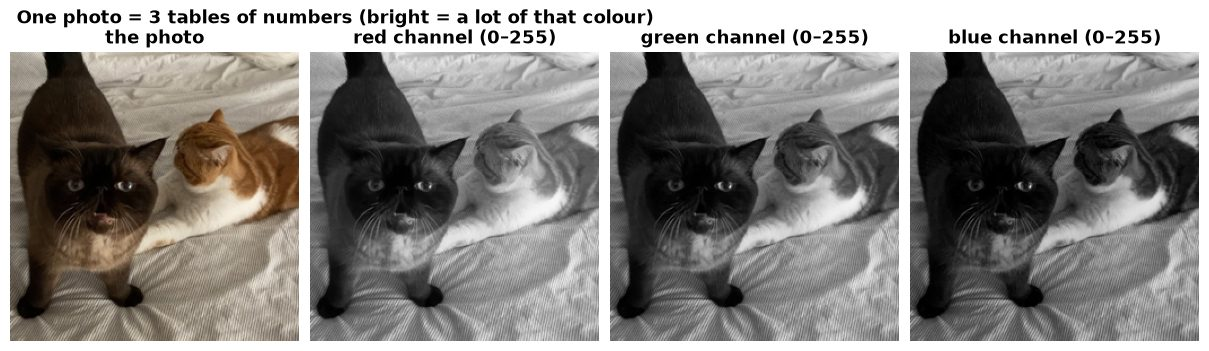

shape: (256, 256, 3) | top-left 3×3 pixels of the red table:
 [[157 185 165]
 [183 166 167]
 [162 159 174]]


In [6]:
star = next(i for i, p in enumerate(pets) if p["name"] == "cat9003")
rgb = np.asarray(ImageOps.fit(pet_imgs[star], (256, 256)))
fig, axes = plt.subplots(1, 4, figsize=(12, 3.4), layout="constrained")
axes[0].imshow(rgb); axes[0].set_title("the photo", loc="center")
for ax, ch, name in zip(axes[1:], range(3), ("red", "green", "blue")):
    ax.imshow(rgb[..., ch], cmap="gray", vmin=0, vmax=255); ax.set_title(f"{name} channel (0–255)", loc="center")
for ax in axes: ax.axis("off")
fig.suptitle("One photo = 3 tables of numbers (bright = a lot of that colour)", x=0.01, ha="left", fontweight="bold")
plt.show()
print("shape:", rgb.shape, "| top-left 3×3 pixels of the red table:\n", rgb[:3, :3, 0])

<a id="sec-2"></a>
# 2. 🔍 A convolution on one of our pets

The same 3 × 3 kernels from notebook 03, now on a real photo of our cat (converted to grey). Each kernel slides over the 65,536 positions; the bright pixels of the output are where its pattern was found. This is **exactly** what the first layer of a CNN computes — except that a CNN learns its own kernels.

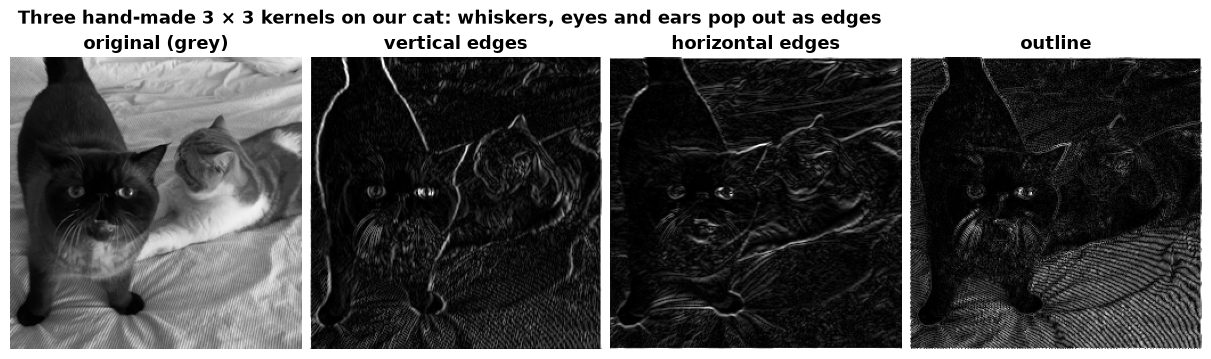

In [7]:
gray = np.asarray(ImageOps.fit(pet_imgs[star], (256, 256)).convert("L"), dtype=np.float32) / 255
panels = [("original (grey)", gray)] + [(name, np.abs(apply_kernel(gray, KERNELS[name])))
                                        for name in ("vertical edges", "horizontal edges", "outline")]
fig, axes = plt.subplots(1, 4, figsize=(12, 3.5), layout="constrained")
for ax, (title, m) in zip(axes, panels):
    ax.imshow(m, cmap="gray", vmin=0, vmax=1 if title.startswith("original") else np.percentile(m, 99.5))
    ax.set_title(title, loc="center"); ax.axis("off")
fig.suptitle("Three hand-made 3 × 3 kernels on our cat: whiskers, eyes and ears pop out as edges", x=0.01, ha="left", fontweight="bold")
save_slide(fig, "cv-kernel-on-pet.webp")
plt.show()

Compare the panels: **vertical edges** catch the sides of the bodies, the ears and the eyes; **horizontal edges** catch the whiskers and the folds of the blanket; the **outline** kernel reacts to every fine texture (fur, fabric). One kernel = one question about the photo.

<a id="sec-3"></a>
# 3. 🎛️ Data augmentation: one photo, many photos

## 🧠 How it works: teach the model what does *not* matter

**Simple idea.** A dog is still a dog if the photo is mirrored, a bit zoomed, slightly rotated or darker. If we show the model these variations **during training**, it learns to ignore them instead of memorising the exact pixels of 2,000 photos.

**Steps:** for every batch, every photo gets a **new random** change → the model never sees exactly the same image twice → it is harder to memorise → less overfitting.

**Analogy.** Studying with exercises that change the numbers each time, instead of memorising the answers of one exam.

**Limits.** Only use changes that keep the label true: flipping a cat left–right is fine; flipping a "6" upside down makes it a "9". Augmentation is for **training only** — validation photos are never changed.

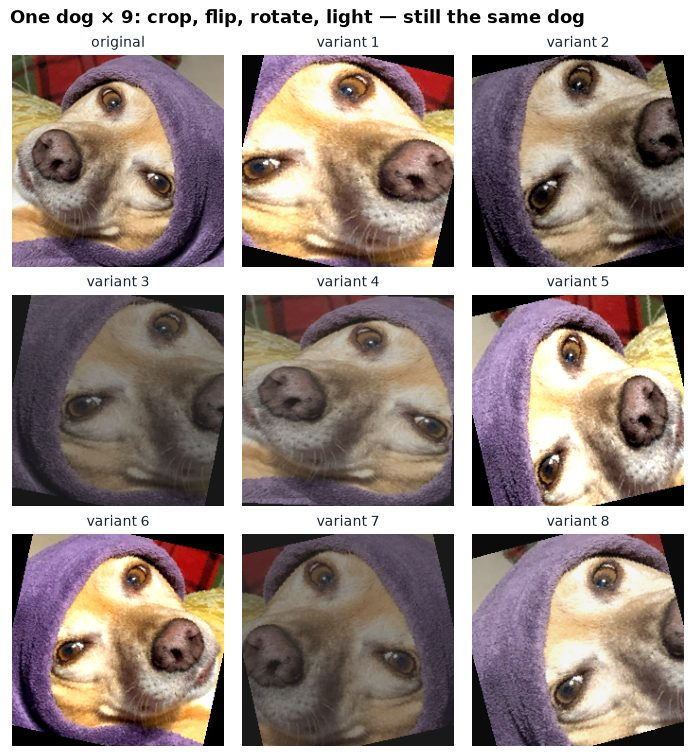

In [8]:
dog = next(i for i, p in enumerate(pets) if p["name"] == "dog9007")
augment = T.Compose([T.RandomResizedCrop(224, scale=(0.55, 1.0)), T.RandomHorizontalFlip(),
                     T.RandomRotation(15), T.ColorJitter(brightness=0.35, contrast=0.35, saturation=0.35)])
torch.manual_seed(3)
variants = [ImageOps.fit(pet_imgs[dog], (224, 224))] + [augment(pet_imgs[dog]) for _ in range(8)]
fig = show_grid(variants, ["original"] + [f"variant {k}" for k in range(1, 9)], ncols=3, size=2.3,
                suptitle="One dog × 9: crop, flip, rotate, light — still the same dog")
save_slide(fig, "cv-augmentation.webp")
plt.show()

For the training below we use a **cheaper** version that runs fast on a CPU: every photo is stored at 144 × 144 and each batch takes a **random 128 × 128 crop** and a **random left–right flip** (`random_crop_flip`). Validation photos get the **centre** 128 × 128 crop.

<a id="sec-4"></a>
# 4. 🧱 A CNN from scratch

In [9]:
cache = cache_dir() / "cats_dogs_144.pt"       # decode the 3,000 JPEGs once, then reuse (≈ 60 MB, git-ignored)
if cache.exists():
    X_tr, X_va = torch.load(cache)
else:
    t0 = time.perf_counter()
    X_tr, X_va = load_images_tensor(p_tr, 144), load_images_tensor(p_va, 144)
    torch.save((X_tr, X_va), cache)
    print(f"images decoded and cached in {time.perf_counter() - t0:.0f} s")
assert len(X_tr) == len(y_tr) and len(X_va) == len(y_va)
print("train:", tuple(X_tr.shape), X_tr.dtype, "| validation:", tuple(X_va.shape))

crop128 = lambda x: center_crop_batch(x, 128)            # validation (and anything we evaluate)
augment128 = lambda x: random_crop_flip(x, 128)          # training only
train_dl = DataLoader(TensorImageDataset(X_tr, y_tr), batch_size=32, shuffle=True,
                      generator=torch.Generator().manual_seed(SEED))
val_dl = DataLoader(TensorImageDataset(X_va, y_va), batch_size=200, shuffle=False)   # fixed order

train: (2000, 3, 144, 144) torch.uint8 | validation: (1000, 3, 144, 144)


## 🧠 How it works: our CNN, block by block

Five blocks of *convolution → batch-norm → ReLU → max-pool*. Each block doubles the number of kernels (16 → 256) and halves the size of the maps (128 → 4 px). Early blocks see edges and colours; later blocks combine them into textures and parts (an ear, an eye, fur).

```
3×128×128 → 16×64×64 → 32×32×32 → 64×16×16 → 128×8×8 → 256×4×4 ─GAP─► 256 numbers ─linear─► 1 logit → P(dog)
```

**Global average pooling (GAP)** turns each of the 256 final maps into **one number**: "how much of pattern *k* is in the photo, wherever it is". Compared with flattening (notebook 03) it needs far fewer weights and works with any photo size. The output is a single number (*logit*); `sigmoid(logit)` = **P(dog)**, and P(cat) = 1 − P(dog).

In [10]:
EPOCHS = 6
set_seed(SEED)
scratch = SmallCNN()                 # channels (16, 32, 64, 128, 256), GAP, dropout 0.2, one logit
print(f"parameters: {count_parameters(scratch):,} | training on {DEVICE} for {EPOCHS} epochs…")
hist_scratch = train_model(scratch, train_dl, val_dl, epochs=EPOCHS, lr=1e-3, device=DEVICE,
                           augment_fn=augment128, input_fn=crop128, cosine=True)
acc_scratch = hist_scratch["acc_va"][-1]
torch.save(scratch.state_dict(), models_dir() / "cats_dogs_scratch_cnn.pt")
print(f"validation accuracy after {EPOCHS} epochs: {acc_scratch:.1%} | "
      f"training time: {sum(hist_scratch['seconds']):.0f} s on {DEVICE}")

parameters: 393,361 | training on cpu for 6 epochs…


epoch  1/6: train loss 0.670 acc 0.601 | val loss 0.616 acc 0.649 | 11.3 s


epoch  2/6: train loss 0.600 acc 0.665 | val loss 0.674 acc 0.603 | 16.4 s


epoch  3/6: train loss 0.559 acc 0.714 | val loss 0.771 acc 0.602 | 12.2 s


epoch  4/6: train loss 0.534 acc 0.738 | val loss 0.584 acc 0.692 | 18.1 s


epoch  5/6: train loss 0.485 acc 0.767 | val loss 0.483 acc 0.778 | 16.8 s


epoch  6/6: train loss 0.457 acc 0.785 | val loss 0.479 acc 0.778 | 15.4 s
validation accuracy after 6 epochs: 77.8% | training time: 90 s on cpu


A few minutes of CPU and the model is clearly better than a coin toss — but far from perfect. What happens if we train **much longer**? Thirty epochs take ≈ 4 minutes per model on a laptop CPU (≈ 15 s on a GPU), so the curves below were computed once and saved; set `RUN_HEAVY = True` to recompute them.

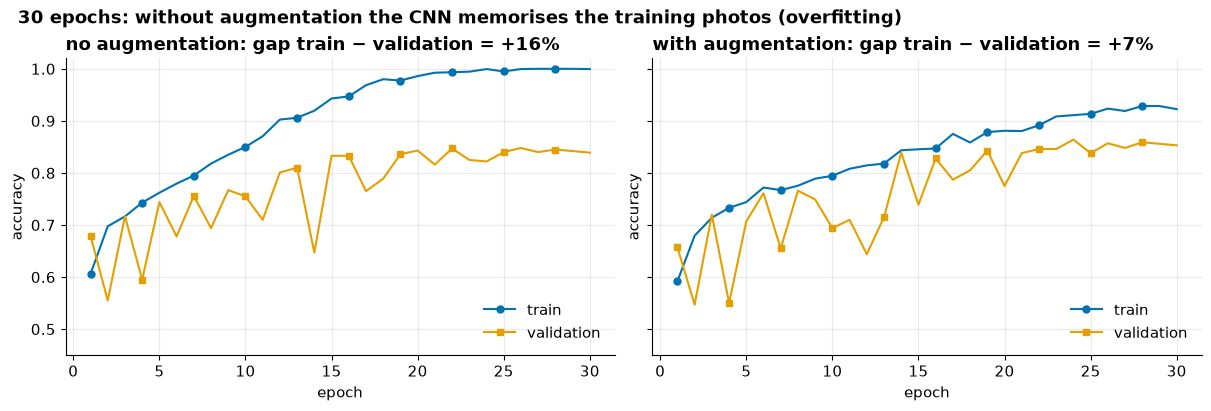

{'no augmentation': 'train 100.0% | validation 83.9% | val loss 0.427', 'with augmentation': 'train 92.2% | validation 85.3% | val loss 0.312'}


In [11]:
if RUN_HEAVY:
    long_runs = {}
    for name, aug in (("no augmentation", None), ("with augmentation", augment128)):
        set_seed(SEED)
        dl = DataLoader(TensorImageDataset(X_tr, y_tr), batch_size=32, shuffle=True, generator=torch.Generator().manual_seed(SEED))
        long_runs[name] = train_model(SmallCNN(), dl, val_dl, epochs=30, lr=1e-3, device=DEVICE,
                                      augment_fn=aug, input_fn=crop128, cosine=True, verbose=False)
else:
    long_runs = json.loads((RESULTS / "heavy_runs.json").read_text(encoding="utf-8"))["scratch"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True, layout="constrained")
for ax, (name, h) in zip(axes, long_runs.items()):
    ep = range(1, len(h["acc_tr"]) + 1)
    ax.plot(ep, h["acc_tr"], marker="o", markevery=3, ms=5, color=PALETTE["blue"], label="train")
    ax.plot(ep, h["acc_va"], marker="s", markevery=3, ms=5, color=PALETTE["orange"], label="validation")
    gap = h["acc_tr"][-1] - h["acc_va"][-1]
    ax.set(title=f"{name}: gap train − validation = {gap:+.0%}", xlabel="epoch", ylabel="accuracy", ylim=(0.45, 1.02))
    ax.legend(loc="lower right")
fig.suptitle("30 epochs: without augmentation the CNN memorises the training photos (overfitting)",
             x=0.01, ha="left", fontweight="bold")
plt.show()
best_scratch = long_runs["with augmentation"]["acc_va"][-1]
print({k: f"train {h['acc_tr'][-1]:.1%} | validation {h['acc_va'][-1]:.1%} | val loss {h['loss_va'][-1]:.3f}"
       for k, h in long_runs.items()})

Without augmentation the training accuracy climbs to almost 100% while validation stalls in the low 80s: the network is **memorising** 2,000 photos. With augmentation the two curves stay close and the validation result is (slightly) better. Even so, ≈ 85% is the ceiling for a small network that has only ever seen 2,000 photos. Section 6 breaks that ceiling.

### 💬 Discussion — Why is 2,000 photos "small"?

Fashion-MNIST had 60,000 images of 784 numbers. Here we have 2,000 photos of 49,152 numbers (128 × 128 × 3). What does that mean for a model that starts knowing nothing?

<details>
<summary>🧑‍🏫 Instructor guide</summary>

Each photo is huge and very varied (pose, breed, background, light), and we have few of them: the model must discover from scratch what an ear, an eye or fur looks like using only 1,000 examples per class. That is why it overfits and plateaus around 80–85%. Two fixes: more data (the full Kaggle set has 25,000 photos and reaches > 95% from scratch) or **reuse knowledge** learned from millions of photos (transfer learning, section 6). Augmentation is a cheap way to "invent" more data.
</details>

<a id="sec-5"></a>
# 5. 🏁 The CPU vs GPU race

## 🧠 How it works: why a graphics card trains faster

**Simple idea.** Training a CNN is **millions of tiny multiplications** (a pixel times a kernel weight) that do not depend on each other. A **CPU** has a few very clever cores (8 here) that work through them a few at a time. A **GPU** has **thousands** of simpler cores (3,072 in an RTX 4060) that do thousands of those multiplications **at the same moment**.

**Analogy.** Painting a huge wall: 8 master painters (CPU) vs 3,000 people with rollers (GPU). For a tiny wall, the masters win (the crowd takes longer to organise); for a big wall, the crowd wins by far.

**A fair race** (`benchmark_training`):

1. **same model, same starting weights** (fixed seed) and **the same batches in the same order**;
2. the photos are **already on the device** (we time the computing, not the copying);
3. a few **warm-up** batches are not counted (the first calls pay one-off start-up costs);
4. we **synchronise** before reading the clock: GPU calls return immediately and finish later — without `torch.cuda.synchronize()` you would time the *order*, not the *work*.

In [12]:
X128 = center_crop_batch(X_tr, 128).contiguous()
Y = torch.as_tensor(y_tr)
live = []
for dev in available_devices():
    r = benchmark_training(SmallCNN, X128, Y, dev, batch_size=32, warmup_batches=3)
    live.append(r)
    print(f"{dev:>4} · {r['device_name']}: one epoch (2,000 photos) in {r['seconds']:.2f} s "
          f"= {r['images_per_second']:,.0f} images/s")

ref = json.loads((RESULTS / "cpu_vs_gpu.json").read_text(encoding="utf-8"))
ref_train = {r["device"]: r for r in ref["training"] if r["batch_size"] == 32}
if len(live) == 1:
    print("\nNo GPU here. Reference numbers measured on the teacher's laptop "
          f"({ref['hardware']['cpu']} + {ref['hardware']['gpu']}):")
    for dev, r in ref_train.items():
        print(f"  {dev:>4}: {r['seconds']:.2f} s per epoch = {r['images_per_second']:,.0f} images/s")
    print("Open this notebook in Colab → Runtime → Change runtime type → T4 GPU to see the race live.")

 cpu · AMD Ryzen 7 7735HS with Radeon Graphics: one epoch (2,000 photos) in 18.79 s = 106 images/s

No GPU here. Reference numbers measured on the teacher's laptop (AMD Ryzen 7 7735HS with Radeon Graphics + NVIDIA GeForce RTX 4060 Laptop GPU):
   cpu: 7.67 s per epoch = 261 images/s
  cuda: 0.52 s per epoch = 3,849 images/s
Open this notebook in Colab → Runtime → Change runtime type → T4 GPU to see the race live.


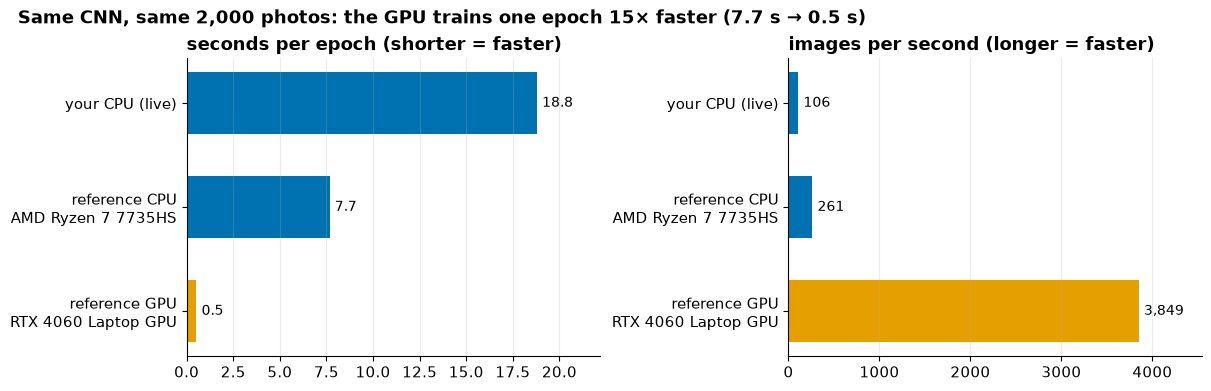

30 epochs: ≈ 3.8 min on the CPU vs ≈ 16 s on the GPU
Using a pretrained MobileNetV3 (section 6), reference: CPU 105 vs GPU 1,871 photos/s (18× faster)


In [13]:
rows = [(f"your {'CPU' if r['device'] == 'cpu' else 'GPU'} (live)", r) for r in live]
if len(live) == 1:   # no GPU: add the reference laptop (CPU and GPU) so the race is still visible
    cpu_label = ref_train["cpu"]["device_name"].split(" with ")[0]
    rows += [(f"reference CPU\n{cpu_label}", ref_train["cpu"]),
             (f"reference GPU\n{ref_train['cuda']['device_name'].replace('NVIDIA GeForce ', '')}", ref_train["cuda"])]
labels = [n for n, _ in rows]
colours = [PALETTE["blue"] if r["device"] == "cpu" else PALETTE["orange"] for _, r in rows]
secs = [r["seconds"] for _, r in rows]
ips = [r["images_per_second"] for _, r in rows]
cpu_s = ref_train["cpu"]["seconds"] if len(live) == 1 else live[0]["seconds"]
gpu_s = ref_train["cuda"]["seconds"] if len(live) == 1 else live[1]["seconds"]
speedup = cpu_s / gpu_s

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), layout="constrained")
for ax, vals, title, dec in ((axes[0], secs, "seconds per epoch (shorter = faster)", 1),
                             (axes[1], ips, "images per second (longer = faster)", 0)):
    ax.barh(range(len(vals)), vals, color=colours, height=0.6)
    ax.set_yticks(range(len(vals)), labels); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
    for k, v in enumerate(vals):
        ax.text(v + max(vals) * 0.015, k, f"{v:,.{dec}f}", va="center", fontsize=10)
    ax.set_xlim(right=max(vals) * 1.18); ax.set_title(title)
fig.suptitle(f"Same CNN, same 2,000 photos: the GPU trains one epoch {speedup:.0f}× faster "
             f"({cpu_s:.1f} s → {gpu_s:.1f} s)", x=0.01, ha="left", fontweight="bold")
save_slide(fig, "cv-cpu-vs-gpu.png")
plt.show()
print(f"30 epochs: ≈ {30 * cpu_s / 60:.1f} min on the CPU vs ≈ {30 * gpu_s:.0f} s on the GPU")
ref_inf = {r["device"]: r for r in ref["inference"]}
print(f"Using a pretrained MobileNetV3 (section 6), reference: CPU {ref_inf['cpu']['images_per_second']:,.0f} vs "
      f"GPU {ref_inf['cuda']['images_per_second']:,.0f} photos/s "
      f"({ref_inf['cuda']['images_per_second'] / ref_inf['cpu']['images_per_second']:.0f}× faster)")

> 💡 **In plain words:** each training step multiplies thousands of pixels by thousands of kernel weights. The GPU does those multiplications **side by side**, the CPU mostly **one after another**. That is the whole secret: not a smarter chip, a much wider one.

> ☁️ **No GPU at home?** Click *Open in Colab* at the top → **Runtime → Change runtime type → T4 GPU** → *Run all*. The race above then runs live on both.

### 💬 Discussion — Do we always need a GPU?

Our small CNN takes ≈ 8 s per epoch on this CPU. When is a GPU worth it, and when is the CPU enough?

<details>
<summary>🧑‍🏫 Instructor guide</summary>

Training big models or many epochs on many photos: GPU (minutes instead of hours; for modern large models there is no alternative). Small experiments, classic ML (Lesson 02), and **using** a trained model for a few photos: the CPU is fine — section 6 shows that, with transfer learning, the expensive part runs **once** and the training takes seconds on a CPU. Remind them of the Lesson 02 benchmark: for tiny matrices the CPU even wins (start-up and copy costs). Also costs and energy: a GPU that sits idle is expensive.
</details>

<a id="sec-6"></a>
# 6. 🎁 Transfer learning: borrow a trained eye

## 🧠 How it works: reuse what a big model already knows

**Simple idea.** Someone already trained a CNN on **1.2 million ImageNet photos** of 1,000 things (including ~120 dog breeds and several cats). Its convolution layers learned edges, textures, fur, eyes, ears… We **keep that "eye" frozen** and only train a tiny new **head** that answers *our* question: cat or dog?

**Steps:**
1. load a pretrained **backbone** from `torchvision` (here **MobileNetV3-Large**: 3 M parameters, designed for phones, fast on a CPU);
2. remove its last layer (the 1,000 ImageNet classes) → for each photo it now outputs a **feature vector** of 960 numbers;
3. run every photo through it **once** and keep the vectors (the slow part: ≈ 30 s on a CPU, cached after the first run);
4. train a **logistic regression** (one `nn.Linear(960, 1)`) on those vectors: **seconds**.

**Analogy.** Hiring an experienced photographer and only explaining the new task, instead of teaching a newborn to see.

**Limits.** It works when our photos look like the photos the backbone saw (ImageNet has plenty of cats and dogs). For X-rays or satellite images, the borrowed eye helps less and we would *fine-tune* deeper layers too.

| Backbone (torchvision) | Parameters | ImageNet top-1 | Speed on CPU |
|---|---|---|---|
| MobileNetV3-Small | 2.5 M | 67.7% | fastest |
| **MobileNetV3-Large** (ours) | 5.5 M (3.0 M without the classifier) | 75.3% | fast |
| EfficientNet-B0 | 5.3 M | 77.7% | ≈ 2× slower |
| ResNet18 | 11.7 M | 69.8% | ≈ 2× slower |

In [14]:
BACKBONE = "mobilenet_v3_large"
backbone, preprocess, n_features = pretrained_backbone(BACKBONE)   # frozen; downloads ≈ 21 MB the first time
print(preprocess)
print(f"feature vector length: {n_features} | trainable parameters in the backbone: {count_parameters(backbone)}")

fcache = cache_dir() / f"features_{BACKBONE}.npz"
if fcache.exists():
    z = np.load(fcache); F_tr, F_va = z["train"], z["validation"]
else:
    t0 = time.perf_counter()
    F_tr, _ = extract_features(backbone, DataLoader(ImageFileDataset(p_tr, y_tr, preprocess), batch_size=64), DEVICE)
    F_va, _ = extract_features(backbone, DataLoader(ImageFileDataset(p_va, y_va, preprocess), batch_size=64), DEVICE)
    np.savez_compressed(fcache, train=F_tr, validation=F_va)
    print(f"features of 3,000 photos computed once in {time.perf_counter() - t0:.0f} s on {DEVICE} (cached for next time)")
assert F_tr.shape == (len(p_tr), n_features) and F_va.shape == (len(p_va), n_features)
print("features:", F_tr.shape, F_va.shape)

ImageClassification(
    crop_size=[224]
    resize_size=[232]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)
feature vector length: 960 | trainable parameters in the backbone: 0
features: (2000, 960) (1000, 960)


In [15]:
t0 = time.perf_counter()
head, hist_head = train_linear_head(F_tr, y_tr, F_va, y_va, epochs=60)
acc_transfer = hist_head["acc_va"][-1]
print(f"new head ({n_features + 1:,} parameters) trained in {time.perf_counter() - t0:.1f} s on the CPU")
print(f"validation accuracy: {acc_transfer:.1%}  (CNN from scratch, {EPOCHS} epochs: {acc_scratch:.1%})")

# extract_features may have moved the backbone to the GPU: the demos below run on the CPU, one photo at a time
clf = PetClassifier(backbone.cpu(), head.cpu()).eval()     # backbone + head = one model, for new photos
torch.save(head.state_dict(), models_dir() / f"cats_dogs_{BACKBONE}_head.pt")

new head (961 parameters) trained in 5.7 s on the CPU
validation accuracy: 98.3%  (CNN from scratch, 6 epochs: 77.8%)


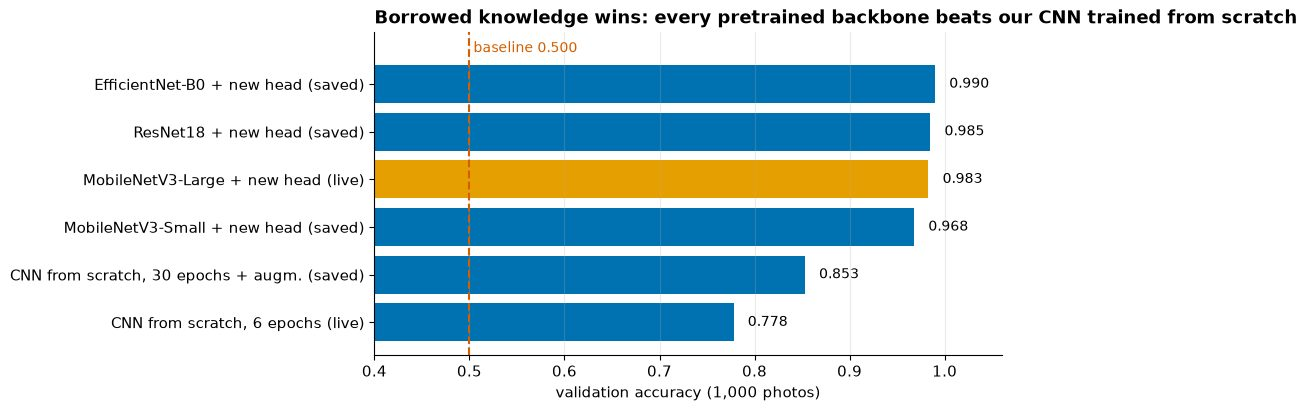

In [16]:
if RUN_HEAVY:
    others = {}
    for name in ("mobilenet_v3_small", "efficientnet_b0", "resnet18"):
        bb, pre, _ = pretrained_backbone(name)
        ftr, _ = extract_features(bb, DataLoader(ImageFileDataset(p_tr, y_tr, pre), batch_size=64), DEVICE)
        fva, _ = extract_features(bb, DataLoader(ImageFileDataset(p_va, y_va, pre), batch_size=64), DEVICE)
        others[name] = {"val_accuracy": train_linear_head(ftr, y_tr, fva, y_va)[1]["acc_va"][-1]}
else:
    others = json.loads((RESULTS / "heavy_runs.json").read_text(encoding="utf-8"))["transfer"]

pretty = {"mobilenet_v3_small": "MobileNetV3-Small", "mobilenet_v3_large": "MobileNetV3-Large",
          "efficientnet_b0": "EfficientNet-B0", "resnet18": "ResNet18"}
scores = {f"CNN from scratch, {EPOCHS} epochs (live)": acc_scratch,
          "CNN from scratch, 30 epochs + augm. (saved)": best_scratch,
          "MobileNetV3-Large + new head (live)": acc_transfer}
scores.update({f"{pretty[k]} + new head (saved)": v["val_accuracy"] for k, v in others.items() if k != BACKBONE})
fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
leaderboard(scores, baseline=0.5, metric="validation accuracy (1,000 photos)", ax=ax,
            highlight="MobileNetV3-Large + new head (live)",
            title="Borrowed knowledge wins: every pretrained backbone beats our CNN trained from scratch")
ax.set_xlim(0.4, 1.06); ax.set_ylim(top=len(scores) + 0.1)
plt.show()

From ≈ 80–85% to ≈ 98% — with **less** computing: the backbone ran once and the head trained in a couple of seconds on a CPU. That is why, in practice, almost nobody trains an image model from scratch: you start from a pretrained one.

### 💬 Discussion — Is it cheating?

The backbone learned from 1.2 million photos that we did not label. Is it fair to compare it with our CNN that saw only 2,000? And what could go wrong when you reuse someone else's model?

<details>
<summary>🧑‍🏫 Instructor guide</summary>

Not cheating — it is the point: knowledge is reusable, like a doctor who studied general anatomy before specialising. But it is not free: (1) the backbone carries the **biases** of ImageNet (mostly Western, well-lit, centred photos); (2) its **licence** and data provenance matter for commercial use; (3) it may not transfer to very different images (medical, industrial); (4) it is bigger and slower than our tiny CNN at prediction time. Comparing fairly means saying what each model was allowed to see.
</details>

<a id="sec-7"></a>
# 7. 📏 Evaluation: confusion matrix and mistakes

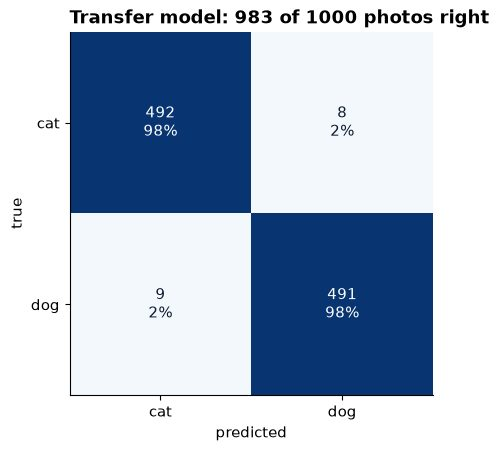

In [17]:
with torch.no_grad():
    p_dog_va = torch.sigmoid(head(torch.as_tensor(F_va)).squeeze(1)).numpy()   # same order as p_va / y_va
pred_va = (p_dog_va >= 0.5).astype(int)
cm = np.zeros((2, 2), dtype=int); np.add.at(cm, (y_va, pred_va), 1)

fig, ax = plt.subplots(figsize=(5.2, 4.4), layout="constrained")
plot_confusion(cm, CLASSES, ax=ax, title=f"Transfer model: {cm.trace()} of {cm.sum()} photos right")
plt.show()

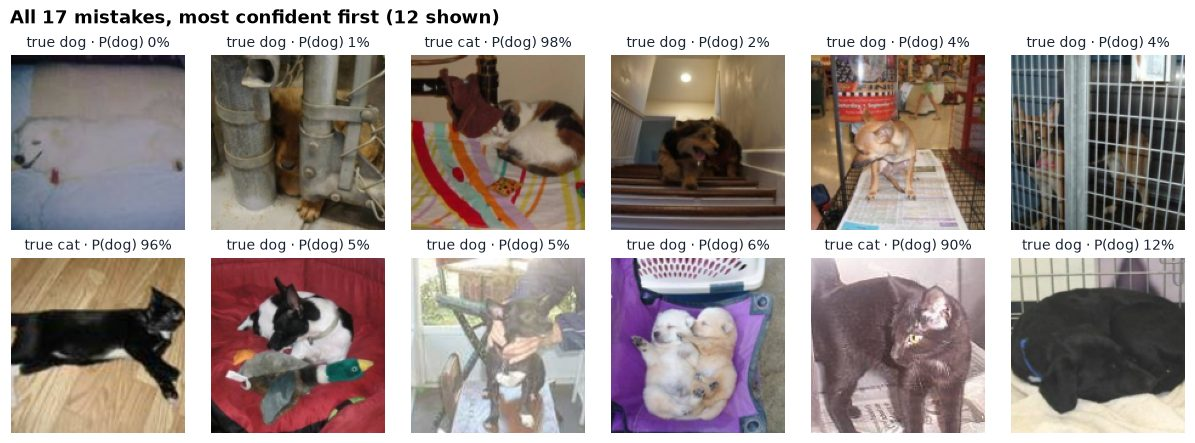

In [18]:
wrong = np.flatnonzero(pred_va != y_va)
wrong = wrong[np.argsort(-np.abs(p_dog_va[wrong] - 0.5))]          # most confident mistakes first
show = wrong[:12]
fig = show_grid([X_va[k] for k in show],
                [f"true {CLASSES[y_va[k]]} · P(dog) {p_dog_va[k]:.0%}" for k in show], ncols=6, size=2.0,
                suptitle=f"All {len(wrong)} mistakes, most confident first ({min(12, len(wrong))} shown)")
plt.show()

Look at *why* it fails: two animals in one photo, a tiny animal in a big scene, an unusual angle, a cartoon or a drawing, a person holding a pet… Some of these photos would be hard to label even for us. The probability tells you **how sure** the model was: a mistake at 55% is a shrug, a mistake at 99% is a real blind spot.

<a id="sec-8"></a>
# 8. 🐶🐱 Our pets: the real test

Validation photos come from the **same collection** as the training photos. The real question is: does it work on **new photos from a different source** — our own animals, taken with a phone at home?

In [19]:
@torch.no_grad()
def p_dog_of(images):
    """P(dog) from the transfer model for a list of PIL images (same preprocessing as in training)."""
    x = torch.stack([preprocess(im) for im in images])
    return torch.sigmoid(clf(x)).numpy()

pets_p = p_dog_of(pet_imgs)
X_pets = load_images_tensor([p["path"] for p in pets], 144)
pets_p_scratch, _ = predict_proba(scratch.cpu(), DataLoader(TensorDataset(crop128(X_pets).float() / 255,
                                  torch.tensor([p["label"] for p in pets])), batch_size=32))
pets_df = pd.DataFrame({"pet": [p["name"] for p in pets], "true": [CLASSES[p["label"]] for p in pets],
                        "P(dog) transfer": pets_p.round(3), "P(dog) from scratch": pets_p_scratch.round(3)})
pets_df["transfer right?"] = (pets_p >= 0.5).astype(int) == [p["label"] for p in pets]
pets_df["scratch right?"] = (pets_p_scratch >= 0.5).astype(int) == [p["label"] for p in pets]
print(f"our 17 pets — transfer model: {pets_df['transfer right?'].sum()}/17 right | "
      f"CNN from scratch: {pets_df['scratch right?'].sum()}/17 right")

# Saved for notebook 05 (CLIP zero-shot vs our trained model)
records = [{"file": p["path"].name, "true": CLASSES[p["label"]], "pred": CLASSES[int(pd_ >= 0.5)],
            "p_dog": round(float(pd_), 6), "model": f"{BACKBONE} + logistic head (cats_and_dogs, 2000 photos)"}
           for p, pd_ in zip(pets, pets_p)]
(RESULTS / "pets_predictions.json").write_text(json.dumps(records, indent=1), encoding="utf-8")
pets_df

our 17 pets — transfer model: 16/17 right | CNN from scratch: 12/17 right


,pet,true,P(dog) transfer,P(dog) from scratch,transfer right?,scratch right?
0,cat10000,cat,0.000,0.833,True,False
1,cat9001,cat,0.000,0.153,True,True
2,cat9002,cat,0.000,0.504,True,False
3,cat9003,cat,0.000,0.210,True,True
4,cat9004,cat,0.000,0.574,True,False
5,cat9005,cat,0.000,0.172,True,True
6,cat9009,cat,0.000,0.446,True,True
7,cat9010,cat,0.000,0.131,True,True
8,cat9013,cat,0.000,0.217,True,True
9,cat9014,cat,0.000,0.322,True,True


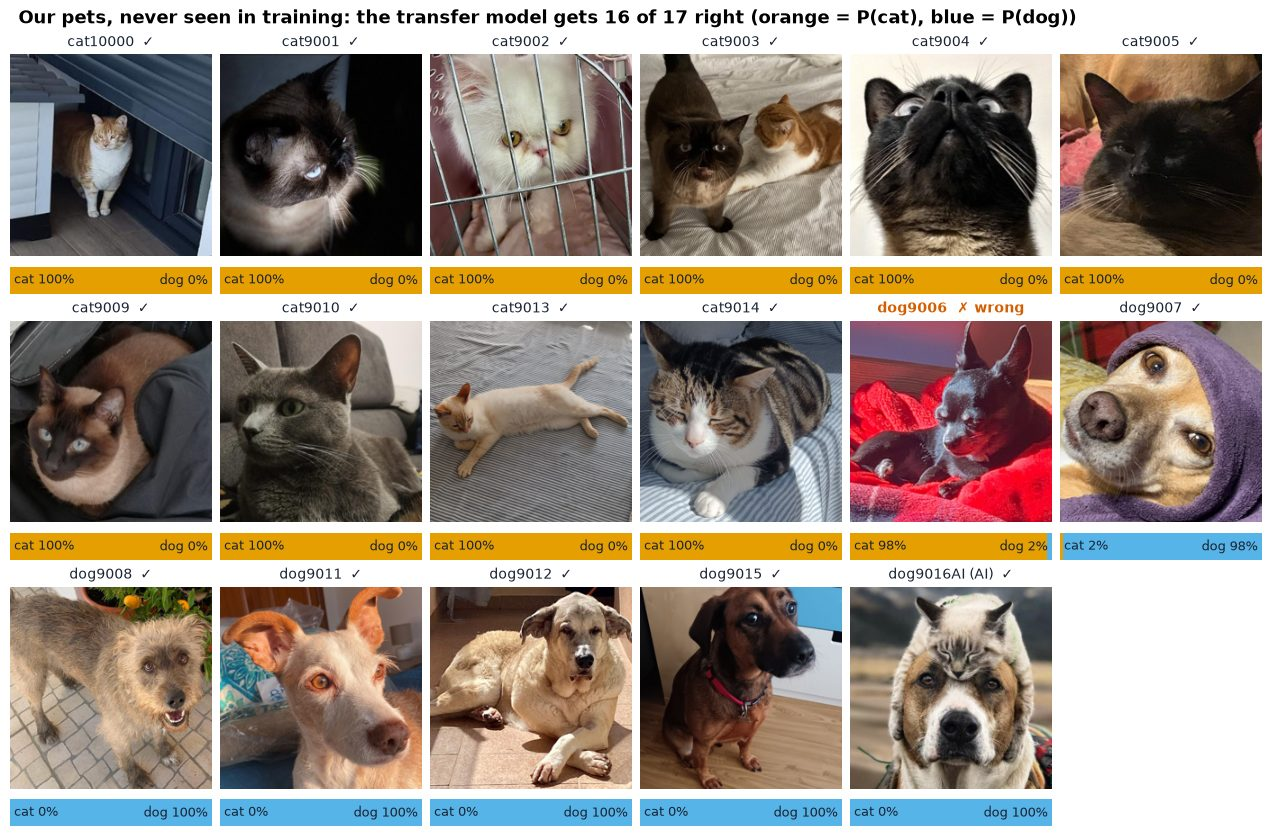

In [20]:
def pet_card_grid(images, names, p_dog, labels, ncols=6, title=""):
    """Each pet: the photo, and below it a bar split into P(cat) and P(dog)."""
    nrows = int(np.ceil(len(images) / ncols))
    fig = plt.figure(figsize=(2.1 * ncols, 2.75 * nrows), layout="constrained")
    grid = fig.add_gridspec(2 * nrows, ncols, height_ratios=[1, 0.13] * nrows)
    for k, (im, name, p, y) in enumerate(zip(images, names, p_dog, labels)):
        r, c = divmod(k, ncols)
        ax = fig.add_subplot(grid[2 * r, c]); ax.imshow(ImageOps.fit(im, (224, 224))); ax.axis("off")
        ok = int(p >= 0.5) == y
        ax.set_title(f"{name}  {'✓' if ok else '✗ wrong'}", fontsize=10, loc="center",
                     color="#1a2433" if ok else PALETTE["red"], fontweight="bold" if not ok else "normal")
        bx = fig.add_subplot(grid[2 * r + 1, c])
        bx.barh(0, 1 - p, color=CLASS_COLORS["cat"], height=1); bx.barh(0, p, left=1 - p, color=CLASS_COLORS["dog"], height=1)
        bx.text(0.02, 0, f"cat {1 - p:.0%}", va="center", ha="left", fontsize=9, color="#1a2433")
        bx.text(0.98, 0, f"dog {p:.0%}", va="center", ha="right", fontsize=9, color="#1a2433")
        bx.set(xlim=(0, 1), ylim=(-0.5, 0.5)); bx.axis("off")
    fig.suptitle(title, x=0.01, ha="left", fontweight="bold")
    return fig

fig = pet_card_grid(pet_imgs, [p["name"] + (" (AI)" if p["ai_generated"] else "") for p in pets], pets_p,
                    [p["label"] for p in pets],
                    title=f"Our pets, never seen in training: the transfer model gets {pets_df['transfer right?'].sum()} of 17 right "
                          "(orange = P(cat), blue = P(dog))")
save_slide(fig, "cv-pets-predictions.webp")
plt.show()

### ✂️ Does cropping change the prediction?

The `original/` photos show the whole scene (sofa, floor, people's legs…); the `cropped/` ones zoom on the animal. Note that the model's own preprocessing also cuts the **central square** of every photo, so in a tall portrait photo part of the animal may be cut off.

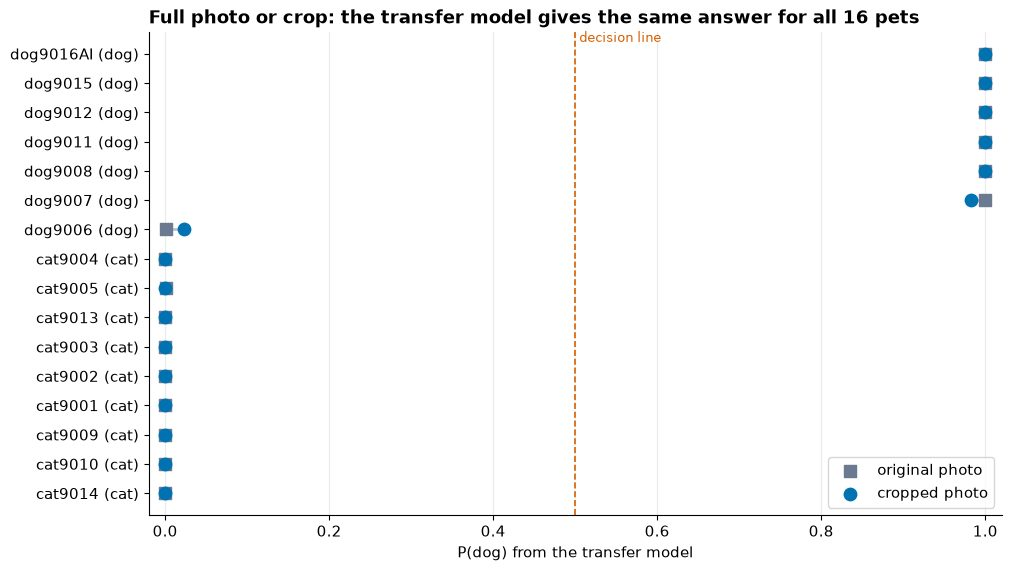

decision changed by cropping: none
transfer model accuracy — original photos: 94% | cropped: 94%


CNN from scratch accuracy — original photos: 88% | cropped: 75% | decision changed for: ['cat9002', 'cat9004']


In [21]:
orig_by_name = {p["name"]: p for p in pets_orig}
both = [p for p in pets if p["name"] in orig_by_name]                       # 16 pets have both versions
orig_imgs = [load_image(orig_by_name[p["name"]]["path"]) for p in both]
p_orig = p_dog_of(orig_imgs)
p_crop = np.array([pets_p[pets.index(p)] for p in both])
labels_both = np.array([p["label"] for p in both])
flips = [(p["name"], po, pc) for p, po, pc in zip(both, p_orig, p_crop) if (po >= 0.5) != (pc >= 0.5)]

order = np.argsort(p_crop)
fig, ax = plt.subplots(figsize=(10, 5.6), layout="constrained")
for row, k in enumerate(order):
    ax.plot([p_orig[k], p_crop[k]], [row, row], color="#b9c3d1", lw=2, zorder=1)
ax.scatter(p_orig[order], range(len(order)), s=70, marker="s", color=PALETTE["grey"], label="original photo", zorder=2)
ax.scatter(p_crop[order], range(len(order)), s=80, marker="o", color=PALETTE["blue"], label="cropped photo", zorder=3)
ax.axvline(0.5, color=PALETTE["red"], ls="--", lw=1.2); ax.text(0.505, len(order) - 0.6, "decision line", color=PALETTE["red"], fontsize=9)
ax.set_yticks(range(len(order)), [f"{both[k]['name']} ({CLASSES[labels_both[k]]})" for k in order])
title = (f"Full photo or crop: the transfer model gives the same answer for all {len(both)} pets" if not flips else
         f"Cropping changed the decision for {len(flips)} of {len(both)} pets")
ax.set(xlabel="P(dog) from the transfer model", xlim=(-0.02, 1.02), title=title)
ax.legend(loc="lower right", frameon=True); ax.grid(axis="y", visible=False)
plt.show()
print("decision changed by cropping:", [(n, f"original {a:.0%} → cropped {b:.0%}") for n, a, b in flips] or "none")
print(f"transfer model accuracy — original photos: {((p_orig >= 0.5) == labels_both).mean():.0%} | "
      f"cropped: {((p_crop >= 0.5) == labels_both).mean():.0%}")

# The CNN trained from scratch on the same 16 pets, full photo vs crop
def p_dog_scratch(paths):
    x = crop128(load_images_tensor(paths, 144)).float() / 255
    with torch.no_grad():
        return torch.sigmoid(scratch.cpu().eval()(x)).numpy()
s_orig = p_dog_scratch([orig_by_name[p["name"]]["path"] for p in both])
s_crop = p_dog_scratch([p["path"] for p in both])
s_flips = [p["name"] for p, a, b in zip(both, s_orig, s_crop) if (a >= 0.5) != (b >= 0.5)]
print(f"CNN from scratch accuracy — original photos: {((s_orig >= 0.5) == labels_both).mean():.0%} | "
      f"cropped: {((s_crop >= 0.5) == labels_both).mean():.0%} | decision changed for: {s_flips or 'none'}")

**What we see (in our run):** for the **transfer model** the crop hardly matters — the probabilities move by a few points and no decision changes; the pretrained backbone finds the animal in a busy scene. The small **CNN from scratch** is more fragile: its accuracy *changes* between the full photos and the crops, and a couple of close-up cat faces flip to "dog" when cropped. Its 2,000 training photos mostly show whole animals at a distance, so a huge face filling the frame is unusual for it. A weak model is sensitive to framing; a strong one much less.

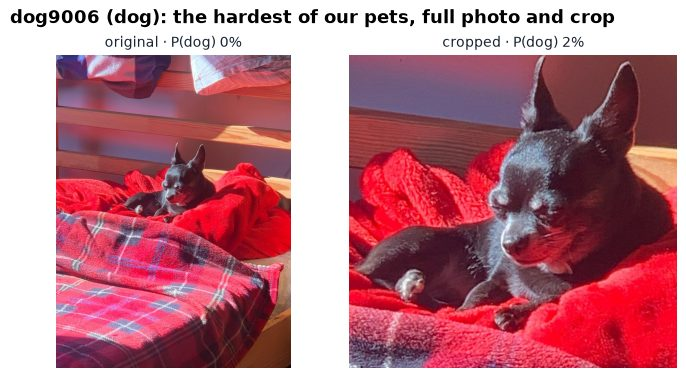

In [22]:
hard = int(np.argmin(np.where(labels_both == 1, p_crop, 1 - p_crop)))   # the pet the model finds hardest
name = both[hard]["name"]
fig = show_grid([orig_imgs[hard], pet_imgs[pets.index(both[hard])]],
                [f"original · P(dog) {p_orig[hard]:.0%}", f"cropped · P(dog) {p_crop[hard]:.0%}"], ncols=2, size=3.4,
                suptitle=f"{name} ({CLASSES[labels_both[hard]]}): the hardest of our pets, full photo and crop")
plt.show()

### 🤖 The AI-generated dog

`dog9016AI` is **not a real photo**: it was generated by an image AI — and look closely: there is a **kitten sitting on the dog's head**. Look at its prediction in the grid above.

In [23]:
ai = next(i for i, p in enumerate(pets) if p["ai_generated"])
print(f"{pets[ai]['name']}: P(dog) = {pets_p[ai]:.1%} (transfer) | {pets_p_scratch[ai]:.1%} (from scratch)")

dog9016AI: P(dog) = 100.0% (transfer) | 97.0% (from scratch)


### 💬 Discussion — Is it real? Does the model care?

The model is confident that this is a dog — and it ignores the kitten. Is it *right*? Could this model tell you whether a photo is real or AI-made? Or that there are **two** animals?

<details>
<summary>🧑‍🏫 Instructor guide</summary>

The model answers exactly the question it was trained on — "cat or dog?" — and an AI-made dog *is* a dog-shaped image, so "dog" is the correct answer to that question. It has no notion of "real vs generated": that is a **different task** that needs its own labelled data (real photos vs generated ones, from many generators), and even then detectors break when new generators appear. Good moment to stress: a model's output is only meaningful for the question and the data it was trained on. Also ethics: generated images of pets are harmless; of people or events, they can mislead — provenance (watermarks, C2PA metadata) matters. The kitten: a single-label classifier must pick **one** answer, so it picks the dominant animal; "both" needs a multi-label model or an object detector (e.g. YOLO), which draws one box per animal.
</details>

### 💬 Discussion — Why does `dog9006` fool the model?

Our small black dog on a red blanket is called a **cat** with high confidence, in the full photo and in the crop. Look at it: what in this photo could look "cat-like" to a model trained on 2,000 Kaggle photos (and ImageNet)? How would you fix it?

<details>
<summary>🧑‍🏫 Instructor guide</summary>

A tiny dog with big upright pointed ears, a small face, curled up on a blanket, in dim light, mostly black: many of those cues are typical of the *cat* photos (cats curled on sofas and blankets are very common in the training set, and black cats are frequent). The Grad-CAM below shows the model's attention spread over the blanket and the ears rather than the snout. Fixes: more photos of small, dark, pointy-eared dog breeds (chihuahuas, pinschers) in training; fine-tuning deeper layers; or simply flag low-quality / unusual photos for a human. One error in 17 also shows why **a real test on new data** matters: validation said 98%, our home photos say 16/17 ≈ 94%.
</details>

## 🔥 Where did the model look? Grad-CAM

## 🧠 How it works

**Simple idea.** The last convolution layer of MobileNetV3 produces 960 small maps (7 × 7) of the photo. **Grad-CAM** asks: *if this map were a bit stronger, would P(dog) — or P(cat) — go up?* (that is the **gradient**). It averages that sensitivity for each map, uses it as the map's weight, adds the weighted maps, and keeps only the positive part. The result is a coarse heatmap, blown up to the photo size: **bright = this region pushed the model towards its answer**.

**Steps (our `GradCAM` class, ~30 lines, only PyTorch hooks):** (1) a *forward hook* keeps the maps of the chosen layer; (2) one backward pass from the score of the predicted class gives their gradients; (3) weight = mean gradient per map; (4) heatmap = ReLU(Σ weight × map), scaled to 0–1.

**Limits.** It is a 7 × 7 sketch, not a pixel-perfect outline, and it shows *where*, not *what* the model saw there. It is a tool to **catch suspicious shortcuts** (e.g. looking at the sofa instead of the animal), not a proof that the model is right.

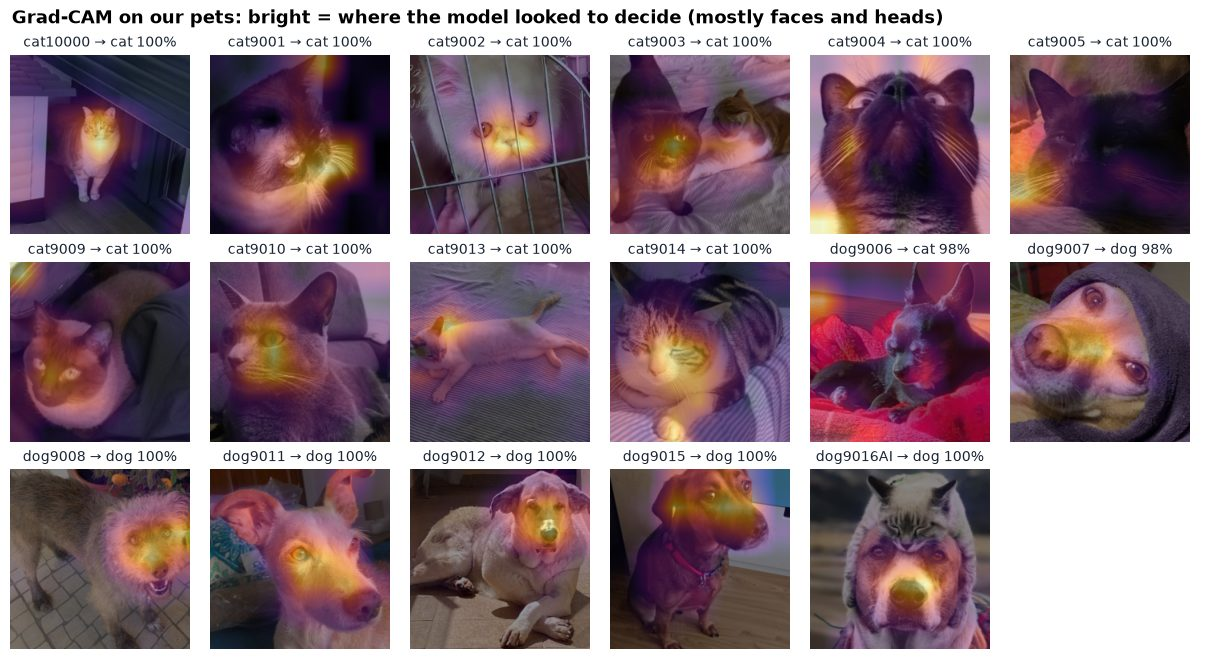

In [24]:
target_layer = clf.backbone.features[-1]               # last conv block of MobileNetV3 (960 maps of 7 × 7)
cams, shown = [], []
with GradCAM(clf, target_layer) as gradcam:
    for im in pet_imgs:
        x = preprocess(im)[None]                         # exactly what the model sees (224 × 224 centre crop)
        heat, p = gradcam(x)                            # explains the predicted class
        cams.append(heat)
        mean, std = torch.tensor([0.485, 0.456, 0.406]), torch.tensor([0.229, 0.224, 0.225])
        shown.append((x[0] * std[:, None, None] + mean[:, None, None]).clamp(0, 1))
overlays = [overlay_heatmap(s, h) for s, h in zip(shown, cams)]
titles = [f"{p['name']} → {'dog' if q >= 0.5 else 'cat'} {max(q, 1 - q):.0%}" for p, q in zip(pets, pets_p)]
fig = show_grid(overlays, titles, ncols=6, size=2.0,
                suptitle="Grad-CAM on our pets: bright = where the model looked to decide (mostly faces and heads)")
save_slide(fig, "cv-gradcam-pets.webp")
plt.show()

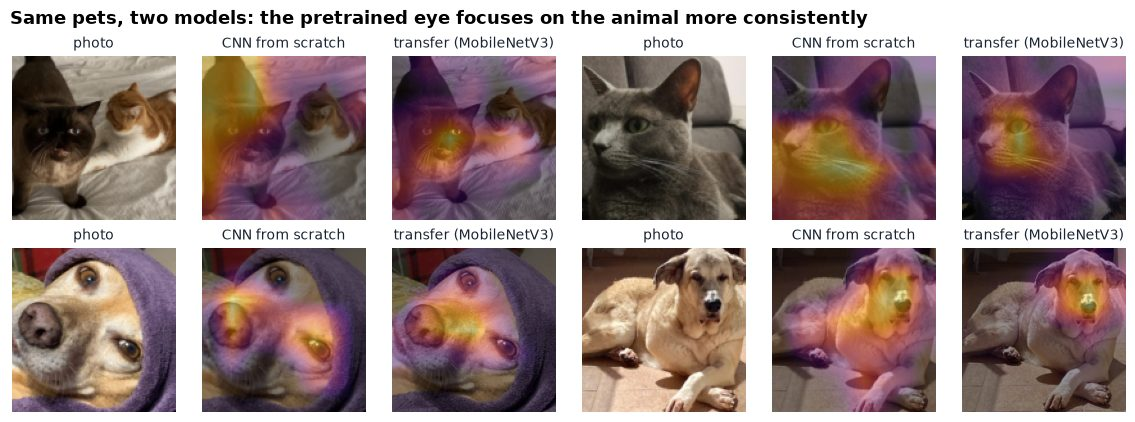

In [25]:
# The model trained from scratch, on the same pets: does it look at the same places?
sel = [i for i, p in enumerate(pets) if p["name"] in ("cat9003", "cat9010", "dog9007", "dog9012")]
scratch = scratch.cpu().eval()                            # trained on DEVICE; the demo runs on the CPU
rows_img = []
with GradCAM(scratch, scratch.features[-2]) as gc:      # last ReLU of our CNN (256 maps of 8 × 8)
    for i in sel:
        x = crop128(X_pets[i:i + 1]).float() / 255
        h, _ = gc(x)
        rows_img += [x[0], overlay_heatmap(x[0], h), overlays[i]]
fig = show_grid(rows_img, ["photo", "CNN from scratch", "transfer (MobileNetV3)"] * len(sel), ncols=3 * 2, size=1.9,
                suptitle="Same pets, two models: the pretrained eye focuses on the animal more consistently")
plt.show()

In [26]:
# Slide asset: a single square Grad-CAM of dog9007, aligned with ImageOps.fit(img, (360, 360))
if EXPORT_SLIDES:
    im = pet_imgs[dog]
    x_sq = normalize_imagenet(T.functional.to_dtype(T.functional.to_image(ImageOps.fit(im, (224, 224))), torch.float32, scale=True))[None]
    with GradCAM(clf, target_layer) as gc:
        h_sq, _ = gc(x_sq)
    sq = overlay_heatmap(np.asarray(ImageOps.fit(im, (360, 360))), h_sq, alpha=0.5)
    out = Image.fromarray((sq * 255).round().astype(np.uint8))
    out.quantize(colors=256, method=Image.Quantize.MEDIANCUT).save(ROOT / "assets" / "slides" / "cv-gradcam-pet.png", optimize=True)

### 💬 Discussion — Would you trust a model that is right for the wrong reason?

Imagine that every dog photo in the training set had been taken outdoors and every cat photo indoors. The model reaches 99% accuracy. What would Grad-CAM show? What happens with a cat in the garden?

<details>
<summary>🧑‍🏫 Instructor guide</summary>

Grad-CAM would light up grass and sofas, not animals: the model learned a **shortcut** ("Clever Hans" effect, named after a horse that seemed to count but was reading its owner's body language). A cat in the garden would be called a dog. Accuracy alone cannot reveal this when the validation photos share the same bias; **looking** at explanations and testing on **different data** (like our pets) can. Real cases: pneumonia models that read the hospital's marker on X-rays, wolf/husky classifiers that looked at snow.
</details>

<a id="sec-9"></a>
# 9. 📸 Try your own photo

`predict_photo` takes a **file path** (or an image) and shows the photo, the Grad-CAM heatmap and the probabilities. Try it with any photo on your computer — a cat, a dog, a fox, a teddy bear, yourself… What does a cat/dog model say about things that are neither?

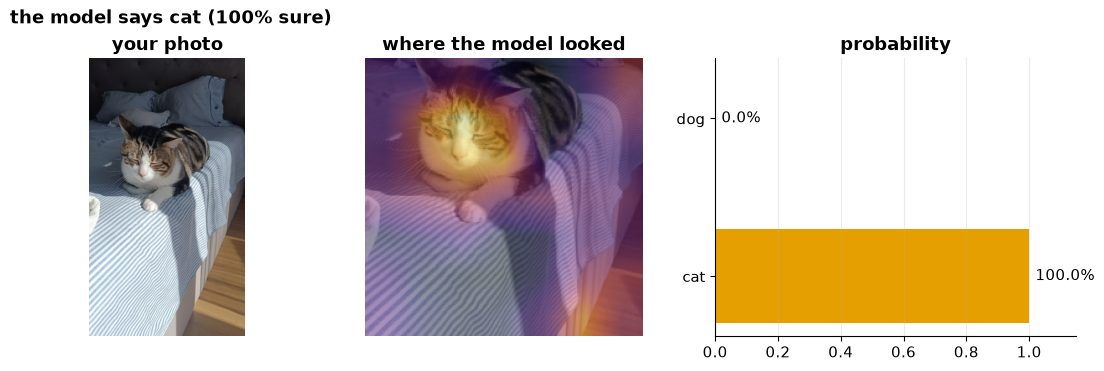

In [27]:
def predict_photo(source, name=None):
    """Predict cat vs dog for a photo (path or PIL image) and show where the model looked."""
    img = source if isinstance(source, Image.Image) else load_image(source)
    x = preprocess(img)[None]
    with GradCAM(clf, clf.backbone.features[-1]) as gc:
        heat, p = gc(x)
    seen = (x[0] * torch.tensor([0.229, 0.224, 0.225])[:, None, None] + torch.tensor([0.485, 0.456, 0.406])[:, None, None]).clamp(0, 1)
    fig, axes = plt.subplots(1, 3, figsize=(11, 3.6), width_ratios=[1, 1, 1.1], layout="constrained")
    axes[0].imshow(img); axes[0].set_title("your photo", loc="center")
    axes[1].imshow(overlay_heatmap(seen, heat)); axes[1].set_title("where the model looked", loc="center")
    for ax in axes[:2]: ax.axis("off")
    axes[2].barh([0, 1], [1 - p, p], color=[CLASS_COLORS["cat"], CLASS_COLORS["dog"]], height=0.6)
    axes[2].set_yticks([0, 1], ["cat", "dog"]); axes[2].set_xlim(0, 1.15); axes[2].grid(axis="y", visible=False)
    for k, v in enumerate((1 - p, p)):
        axes[2].text(v + 0.02, k, f"{v:.1%}", va="center")
    axes[2].set_title("probability", loc="center")
    verdict = "dog" if p >= 0.5 else "cat"
    fig.suptitle((f"{name}: " if name else "") + f"the model says {verdict} ({max(p, 1 - p):.0%} sure)", x=0.01, ha="left", fontweight="bold")
    plt.show()
    return p

# Example: a full (uncropped) photo of one of our cats. Replace with your own path, e.g. predict_photo("Pictures/rex.jpg")
_ = predict_photo(orig_by_name["cat9014"]["path"])

In [28]:
# Or upload a photo with a button
def open_upload(content):
    return ImageOps.exif_transpose(Image.open(io.BytesIO(bytes(content)))).convert("RGB")

def uploaded_files(value):
    """(name, bytes) pairs from a FileUpload value: ipywidgets 7 (dict by name) or 8 (tuple of records)."""
    if isinstance(value, dict):
        return [(name, f["content"]) for name, f in value.items()]
    return [(f["name"], f["content"]) for f in value]

if IN_COLAB:   # Colab: its own upload dialog (press "Cancel upload" to skip)
    from google.colab import files
    for name, content in files.upload().items():
        predict_photo(open_upload(content), name=name)
else:
    try:
        import ipywidgets as widgets

        upload = widgets.FileUpload(accept="image/*", multiple=False, description="Upload a photo")
        output = widgets.Output()

        def on_upload(change):
            with output:
                output.clear_output()
                for name, content in uploaded_files(upload.value):
                    predict_photo(open_upload(content), name=name)

        upload.observe(on_upload, names="value")
        display(widgets.VBox([upload, output]))
    except ImportError:
        print("ipywidgets is not installed: use predict_photo('path/to/photo.jpg') instead.")

> 💡 **Tip:** the model **always** answers "cat" or "dog", even for a car. A probability of 99% does not mean "this is surely a dog"; it means "between *cat* and *dog*, this looks much more like *dog*". Knowing when to say "neither" requires training with a third class (or the CLIP approach of notebook 05).

<a id="sec-10"></a>
# 10. ✏️ Exercises

### ✏️ Exercise 1 — Your own kernel on your favourite pet

**Difficulty:** ⭐

Pick another pet from `pets` and apply `KERNELS["sharpen"]` and `KERNELS["blur"]` (or a 5 × 5 blur you write yourself) to its grey version. What happens to the fur?

In [29]:
# TODO: g = np.asarray(ImageOps.fit(pet_imgs[0], (256, 256)).convert("L"), dtype=np.float32) / 255
# TODO: show_grid([g, apply_kernel(g, KERNELS["sharpen"]), apply_kernel(g, np.full((5, 5), 1 / 25))], ...)

<details>
<summary>💡 Show solution</summary>

Sharpen makes the fur look crisper (and noisier); a 5 × 5 blur averages 25 pixels and erases the fine fur texture. A CNN can learn both kinds of kernels.

```python
g = np.asarray(ImageOps.fit(pet_imgs[0], (256, 256)).convert("L"), dtype=np.float32) / 255
outs = [g, apply_kernel(g, KERNELS["sharpen"]), apply_kernel(g, np.full((5, 5), 1 / 25, dtype=np.float32))]
show_grid([np.clip(o, 0, 1) for o in outs], ["grey", "sharpen", "blur 5×5"], ncols=3, size=3.2); plt.show()
```
</details>

### ✏️ Exercise 2 — The photos the model is least sure about

**Difficulty:** ⭐⭐

Using `p_dog_va`, find the 12 validation photos with P(dog) **closest to 0.5** and show them with their probability. What do they have in common?

In [30]:
# TODO: unsure = np.argsort(np.abs(p_dog_va - 0.5))[:12]; show_grid([X_va[k] for k in unsure], ...)

<details>
<summary>💡 Show solution</summary>

Typically: both a cat and a dog in the photo, the animal very small or partly hidden, unusual breeds, puppies/kittens that look alike, or drawings. In a real app these are the photos to send to a human.

```python
unsure = np.argsort(np.abs(p_dog_va - 0.5))[:12]
show_grid([X_va[k] for k in unsure], [f"{CLASSES[y_va[k]]} · P(dog) {p_dog_va[k]:.0%}" for k in unsure], ncols=6, size=2); plt.show()
```
</details>

### ✏️ Exercise 3 — Try to fool the model

**Difficulty:** ⭐⭐

Take one of our dogs and change the photo with PIL: rotate it 90° (`im.rotate(90, expand=True)`), make it grey (`im.convert("L").convert("RGB")`), keep only the top-left quarter, or flip it upside down (`ImageOps.flip(im)`). Which change hurts P(dog) the most? Use `predict_photo` or `p_dog_of`.

In [31]:
im = pet_imgs[dog]
# TODO: variants = {"original": im, "rotated 90°": ..., "grey": ..., "upside down": ..., "top-left quarter": ...}
# TODO: print P(dog) of each with p_dog_of(list(variants.values()))

<details>
<summary>💡 Show solution</summary>

Grey and mirrored photos barely matter (ImageNet has many). Rotations and upside-down photos usually lower the confidence — the training photos were almost all upright, and we did not augment with big rotations. A crop without the head is the hardest: Grad-CAM showed the face carries most of the evidence.

```python
w, h = im.size
variants = {"original": im, "rotated 90°": im.rotate(90, expand=True), "grey": im.convert("L").convert("RGB"),
            "upside down": ImageOps.flip(im), "top-left quarter": im.crop((0, 0, w // 2, h // 2))}
for name, p in zip(variants, p_dog_of(list(variants.values()))):
    print(f"{name:>17}: P(dog) = {p:.1%}")
```
</details>

### ✏️ Exercise 4 — Another backbone

**Difficulty:** ⭐⭐⭐

Repeat section 6 with `"resnet18"` or `"mobilenet_v3_small"` instead of MobileNetV3-Large: extract the features (≈ 1 min on a CPU), train the head, and compare the validation accuracy **and** the predictions on our 17 pets. Is the most accurate backbone also the best on our pets?

In [32]:
# TODO: bb, pre, nf = pretrained_backbone("resnet18")
# TODO: extract_features(...) for train and validation, train_linear_head(...), then predict the pets

<details>
<summary>💡 Show solution</summary>

All backbones land around 97–99% on validation (see the leaderboard); on 17 pets the differences are one or two photos, so **17 photos are too few to rank models** — a good reminder about test-set size. The speed differences are real, though: MobileNetV3-Small is ≈ 3× faster than ResNet18 on a CPU.

```python
bb, pre, nf = pretrained_backbone("resnet18")
ftr, _ = extract_features(bb, DataLoader(ImageFileDataset(p_tr, y_tr, pre), batch_size=64))
fva, _ = extract_features(bb, DataLoader(ImageFileDataset(p_va, y_va, pre), batch_size=64))
h2, hist2 = train_linear_head(ftr, y_tr, fva, y_va)
model2 = PetClassifier(bb, h2).eval()
with torch.no_grad():
    p2 = torch.sigmoid(model2(torch.stack([pre(im) for im in pet_imgs]))).numpy()
print(f"validation {hist2['acc_va'][-1]:.1%} | pets right: {((p2 >= 0.5) == [p['label'] for p in pets]).sum()}/17")
```
</details>

<a id="sec-11"></a>
# 11. 📌 Summary

In [33]:
print(f"Notebook run time: {(time.perf_counter() - T_START) / 60:.1f} min on this machine ({DEVICE})")

Notebook run time: 2.7 min on this machine (cpu)


| Idea | In one line |
|---|---|
| **Colour photo** | three tables of numbers (red, green, blue) |
| **Explicit file lists** | labels come from the folder, order is fixed; evaluation loaders never shuffle |
| **Convolution on a photo** | a 3 × 3 kernel finds edges in a real photo of our cat — what a CNN's first layer does |
| **Data augmentation** | random crops/flips/light during training → less overfitting |
| **CNN from scratch** | ≈ 80–85% with 2,000 photos; without augmentation it memorises (train ≈ 99%) |
| **CPU vs GPU** | same model, same batches: the GPU trains ≈ 15× faster (thousands of multiplications in parallel) |
| **Transfer learning** | frozen pretrained backbone + new head trained in seconds → ≈ 98% |
| **Our pets** | new photos from a new source are the real test; cropping and framing change the probabilities |
| **Grad-CAM** | a heatmap of where the model looked: a tool to catch shortcuts, not a proof |

**Checklist:** ☐ file lists and labels checked, evaluation not shuffled? ☐ augmentation only on training data? ☐ overfitting checked with train vs validation curves? ☐ a pretrained backbone tried before training from scratch? ☐ tested on photos from a *different* source? ☐ looked at mistakes and heatmaps, not only the accuracy?

<a id="sec-12"></a>
# 12. 📚 Learn more

- PyTorch tutorial, *Transfer Learning for Computer Vision*: <https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html>
- torchvision, *Models and pre-trained weights* (the weights API, `weights.transforms()`, accuracy and size of every backbone): <https://docs.pytorch.org/vision/stable/models.html>
- Selvaraju et al. (2017), *Grad-CAM: Visual Explanations from Deep Networks via Gradient-based Localization*: <https://arxiv.org/abs/1610.02391>
- Howard et al. (2019), *Searching for MobileNetV3*: <https://arxiv.org/abs/1905.02244>
- Elson et al. (2007), *Asirra: a CAPTCHA that exploits interest-aligned manual image categorization* (where the cats and dogs come from): <https://www.microsoft.com/en-us/research/publication/asirra-a-captcha-that-exploits-interest-aligned-manual-image-categorization/>

---
<div align="center">

⬅️ [Previous: 03 · Computer Vision basics](../01_mini_project_fashion_mnist/03_Computer_Vision_Basics_Fashion_MNIST.ipynb) &nbsp;·&nbsp; 🏠 [Lesson 03](../../README.md) &nbsp;·&nbsp; [Next: Challenge 2 · YOLO scavenger hunt](../03_challenge_yolo/Challenge_2_YOLO_Scavenger_Hunt.ipynb) ➡️

**The AI Learning Hub** · Lesson 03 — Applied AI: unstructured data<br>
MIT License

</div>